# Topic analysis: policy relationships in NCSL summaries

**Research question:** Do state AI measures share governance approaches across application domains and jurisdictions, and do measures in the same existing category differ in what they require?

研究對象：**從 NCSL 法案摘要辨識政策主題，再以資料庫保存的條文驗證跨領域關係。**

This notebook starts with the requested eight-topic TF–IDF/NMF baseline, inspects all 40 representatives, and then compares limited cleaning and model settings. NCSL categories, states, political control, generated summaries, and the seven supplied scores **never enter the topic models**. `Bill_Text` is used only for subsequent case verification. This is exploratory analysis of a captured corpus, not measurement of current law or a supervised feature generator.

Run from the repository root or `notebooks/`. First run `python -m pip install -r requirements.txt` and `python src/prepare.py`. Run all cells in order. Outputs go to `outputs/topic_analysis/`; the original prepared table is unchanged. The LDA appendix can be disabled with `INCLUDE_LDA = False` without disabling the NMF analysis.

In [1]:
from pathlib import Path
import sys, json, hashlib, warnings, importlib.metadata, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, HTML, Markdown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/prepare.py").exists() and (p / "notebooks").exists()), None)
if root is None:
    raise FileNotFoundError("Run inside the siads696-state-of-ai repository")
sys.path.insert(0, str(root))
from src.topic_analysis import (
    TEXT, IDENTIFIERS, LEGAL_STOPWORDS, GEOGRAPHIC_NAMES, CATEGORY_REPAIRS, CATEGORY_ALIASES,
    sha256, load_common, topic_tables, dominant_topics, run_experiments,
    distributions, heatmap, case_evidence, pair_stability, model_review_notes,
    stability_report, scaling_sensitivity, check_topic_identity, supplementary_analysis, sponsor_tables,
)
OUT = root / "outputs/topic_analysis"
OUT.mkdir(parents=True, exist_ok=True)
INCLUDE_LDA = True  # secondary bounded comparison, after the initial NMF review
BASE_ID = "nmf_baseline_k8_seed42_nndsvda"
CLEAN_ID = "nmf_legal_k8_seed42_nndsvda"
EXPECTED_RAW_SHA256 = "188aba4f4e50c6d0acb3532d143b9a81d9cccdf7c0729ba7ded6410399eff232"
assert sha256(root / "data/raw/Final_Database.csv") == EXPECTED_RAW_SHA256, (
    "Source changed: review the fixed case selections and labels before reusing them")

pd.set_option("display.max_colwidth", None)
def show(frame):
    display(HTML(frame.to_html(index=False, escape=True).replace(
        '<table ', '<table style="font-size:12px;table-layout:auto;overflow-wrap:anywhere" ')))
display(HTML('<style>td {vertical-align:top; white-space:normal!important;} th {text-align:left;} .dataframe {max-width:100%;}</style>'))
print("Repository:", root)
print("Input: data/processed/common_intake/common_records.csv")
labels = json.loads((root / "notebooks/topic_labels.json").read_text(encoding="utf-8"))
reference_path = OUT / "summary_nmf_models.joblib"
reference_models = joblib.load(reference_path) if reference_path.exists() else None
migration = labels["reviewed_migration"]
reviewed_migration = (reference_models is not None
    and sha256(reference_path) == migration["reference_model_sha256"]
    and sha256(root / "data/processed/common_intake/common_records.csv") == migration["common_records_sha256"])
identity_audit = []


Repository: C:\Users\chian\OneDrive\Desktop\SIADS_696\siads696-state-of-ai
Input: data/processed/common_intake/common_records.csv


## 1. Shared intake and analysis population

Josue's `src/prepare.py` normalizes Unicode with NFKC and whitespace, retaining words and punctuation and keeps the last record for each identical cleaned Bill_Text. Retained original fields are checked by source_row; Sponsor_Party is compared as a parsed list. **`source_row` is a one-based record position, not a CSV physical line number or a verified unique-bill identifier.** Only empty `NCSL_Summary_clean` would be excluded. Missing lowercase `summary`, categories, outcomes or other fields do not cause removal.

Category labels are used only for post-fit interpretation; they never enter the fitted features. Both semicolons and commas separate labels; slashes inside labels remain. `Associated Bills:` and `Summary:` spillover is discarded from the category copy. Three observed missing separators and three spelling/short-name aliases are repaired explicitly below. Original category text remains in the representative and case tables; labels are never inferred from summaries.

In [2]:
# Also checks every original field, row position and prepared text against the raw snapshot.
work, audit = load_common(root)
show(pd.DataFrame(audit.items(), columns=["check", "records_or_value"]))
(OUT / "data_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
category_audit = work[["source_row", "NCSL_Category"]].copy()
category_audit["parsed_categories"] = work.categories.map(lambda x: "; ".join(x))
category_audit.to_csv(OUT / "category_parsing_audit.csv", index=False)
show(pd.DataFrame([{"original": k, "parsed": v, "reason": "Missing separator"}
                   for k, v in CATEGORY_REPAIRS.items()] +
                  [{"original": k, "parsed": v, "reason": "Observed case/short-name alias"}
                   for k, v in CATEGORY_ALIASES.items()]))
print("Parsed category inventory:", sorted({c for labels in work.categories for c in labels}))
print(f"Retained {audit['empty_other_summary_retained']} empty publisher-generated summaries.")
assert len(work) == audit["included_records"] and work.source_row.is_unique
assert not work[TEXT].str.strip().eq("").any()

check,records_or_value
raw_records,2571
prepared_columns,45
removed_fulltext_duplicates,"[{'removed_source_row': '71', 'retained_source_row': '1627', 'raw_text_identical': False, 'removed_raw_sha256': '7977fd4e6c129e4221ab041cb35099b8c8f7ee4bd568c839302c39957c9a82b6', 'retained_raw_sha256': 'a415b05cdc57ffd4ffb7e5e022e3b4a3c404002bfe29336b6aa4ad170a7cace1', 'clean_text_sha256': '309b002864937f61b4f66834b66c66c67b5dc48b1e58aaee6b55d77b8aa1f22d'}, {'removed_source_row': '92', 'retained_source_row': '1659', 'raw_text_identical': False, 'removed_raw_sha256': '21e44239440cdade2f989835ff45140e9ddbd68792580633442b2134b07c72f3', 'retained_raw_sha256': 'c9ce0521e41c5808c05373d31ba2854743e14cfbbf2e116df26fb87e736ca5ea', 'clean_text_sha256': '16b7e7dfdf146f02978a1366d246ca081fbb48bf9e01b08a5e76f20c14489340'}, {'removed_source_row': '244', 'retained_source_row': '1921', 'raw_text_identical': True, 'removed_raw_sha256': '6e12e5067422ab9f316591d79f400d0a28daae7097b39f7a855cde0efc0c9acf', 'retained_raw_sha256': '6e12e5067422ab9f316591d79f400d0a28daae7097b39f7a855cde0efc0c9acf', 'clean_text_sha256': '44df04deb601181a9262bfde84f5410b127e1509730ed5058cf26740bbb4de22'}, {'removed_source_row': '263', 'retained_source_row': '1958', 'raw_text_identical': False, 'removed_raw_sha256': '748bd5044500fa2d54ad52ab0d43bf8b243b0f080ff3671d7e999150664f795a', 'retained_raw_sha256': 'd37e5636be6782723673555c42fdd1ac9678cfc0ccd5d335010700ba1a749f4d', 'clean_text_sha256': 'b88bd48cdc7d1be3006735719c3823634ab233acba0c2d435fd199a618fa2d60'}]"
source_records,2567
included_records,2567
excluded_empty_ncsl_summary,0
empty_other_summary_retained,484
blank_category_field,238
no_category_after_parsing,264
category_associated_bills_spillover,231


original,parsed,reason
Effect on Labor/Employment Government Use,Effect on Labor/Employment; Government Use,Missing separator
Effect on Labor/Employment Studies,Effect on Labor/Employment; Studies,Missing separator
Notification Private Sector Use,Notification; Private Sector Use,Missing separator
Government use,Government Use,Observed case/short-name alias
Health use,Health Use,Observed case/short-name alias
Private Sector,Private Sector Use,Observed case/short-name alias


Parsed category inventory: ['Appropriations', 'Audit', 'Child Pornography', 'Criminal Use', 'Cybersecurity', 'Deepfake', 'Education Use', 'Education/Training', 'Effect on Labor/Employment', 'Elections', 'Energy', 'Government Use', 'Health Use', 'Housing', 'Impact Assessment', 'Judicial Use', 'Notification', 'Oversight/Governance', 'Personhood', 'Private Right of Action', 'Private Sector Use', 'Provenance', 'Responsible Use', 'Studies', 'Taxes']
Retained 484 empty publisher-generated summaries.


In [3]:
display(Markdown(f"**Observed coverage:** {audit['raw_records']:,} raw records become {audit['source_records']:,} prepared records after {len(audit['removed_fulltext_duplicates'])} cleaned-full-text duplicate removals. {audit['included_records']:,} summaries enter the model; {audit['no_category_after_parsing']} have no usable category. There are {audit['duplicate_clean_summary_extra_records']} extra occurrences of identical cleaned summaries. Counts describe records, not independent policy initiatives."))

**Observed coverage:** 2,571 raw records become 2,567 prepared records after 4 cleaned-full-text duplicate removals. 2,567 summaries enter the model; 264 have no usable category. There are 260 extra occurrences of identical cleaned summaries. Counts describe records, not independent policy initiatives.

## 2. Requested first model: eight topics and five representatives each

English stopwords, unigrams/bigrams, `min_df=3`, `max_df=0.85`; NMF with eight components, NNDSVDa initialization, seed 42 and 500 maximum iterations. The only text supplied to the vectorizer is `NCSL_Summary_clean`. No custom policy or domain dictionary guides this fit.

Representatives are ranked by the **raw fitted weight for each topic across all records**, with stable row order for exact ties. A representative need not have that topic as its largest weight. These are diagnostic examples, not a representative statistical sample. NMF weights are nonnegative loadings, not probabilities; row-normalized weights are descriptive shares only.

In [4]:
vectorizer = TfidfVectorizer(
    stop_words="english", ngram_range=(1, 2), min_df=3, max_df=0.85)
X = vectorizer.fit_transform(work[TEXT])
model = NMF(n_components=8, init="nndsvda", random_state=42, max_iter=500)
import time
started = time.perf_counter()
with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=2):
    warnings.simplefilter("always", ConvergenceWarning)
    document_weights = model.fit_transform(X)
baseline = dict(vectorizer=vectorizer, X=X, model=model, W=document_weights,
                seconds=time.perf_counter()-started, warnings=[str(w.message) for w in caught])

identity_audit.extend({"variant": "baseline", **row} for row in check_topic_identity(
    baseline, labels["baseline"], reference_models["baseline"] if reference_models else None,
    migration["baseline"] if reviewed_migration else None))

terms = vectorizer.get_feature_names_out()
baseline_topics, baseline_reps = topic_tables(work, model, document_weights, vectorizer, BASE_ID)
baseline_reps.to_csv(OUT / "baseline_representative_bills.csv", index=False)
print(f"TF-IDF shape: {X.shape}; NMF iterations: {model.n_iter_}")
zero_rows = work.loc[X.getnnz(axis=1) == 0, IDENTIFIERS + [TEXT]]
show(zero_rows)
print("Zero-vector records are retained and marked topic -1 (unassigned), never topic 0.")
assert len(baseline_reps) == 40
for topic in baseline_topics.itertuples():
    display(Markdown(f"### Topic {topic.topic_id} — {topic.keywords}"))
    show(baseline_reps.loc[baseline_reps.topic_id.eq(topic.topic_id),
         ["rank", *IDENTIFIERS, "NCSL_Category", "parsed_categories", TEXT,
          "topic_weight_raw", "dominant_topic"]])

TF-IDF shape: (2567, 6444); NMF iterations: 48


source_row,Jurisdiction,Bill_Number,Year,NCSL_Summary_clean
207,Illinois,HR 142,2025,Mourns the passing of Max Jordan Chiswick.


Zero-vector records are retained and marked topic -1 (unassigned), never topic 0.


### Topic 0 — ai, state, requires, department, education, certain, technology, establishes, school, public, program, board

rank,source_row,Jurisdiction,Bill_Number,Year,NCSL_Category,parsed_categories,NCSL_Summary_clean,topic_weight_raw,dominant_topic
1,289,Maryland,S 704,2025,Education Use; Studies; Government Use,Education Use; Government Use; Studies,Requires the State Department of Education to conduct an evaluation on the use and potential use of AI in public schools; requires that the evaluation consist of a survey of local school systems and a review of available systems that use AI to assist with student learning; requires the Department of Information Technology to assist the State Department of Education in performing its review; requires the Department to issue a final report on the results.,0.117941,0
2,277,Maryland,H 981,2025,Studies; Education Use,Education Use; Studies,Requires the State Department of Education to conduct an evaluation on the use and potential use of AI in public schools; requires that the evaluation consist of a survey of local school systems and a review of available systems that use AI to assist with student learning; requires the Department of Information Technology to assist the State Department of Education in performing its review.,0.112186,0
3,293,Maryland,S 906,2025,Education Use; Studies; Government Use,Education Use; Government Use; Studies,"Requires the State Department of Education, in consultation with the State Board of Education and the Task Force on AI in K-12 Education, to develop or update guidance on AI for county boards of education; requires the Department, in consultation with the Department of Information Technology, to develop and update annually a list of approved AI tools; requires each county board to conduct an annual inventory of systems.",0.107577,0
4,2448,Utah,H 273,2026,Education Use,Education Use,"Requires the State Board of Education to create model policies on the use of technology and artificial intelligence in a public school classroom, defines terms, requires the State Board of Education to include certain technology standards in core education standards, creates certain requirements for a local education agency related to the use of technology in the classroom, requires the state board to create a model policy on the balanced use of technology in the classroom and use of AI in the classroom.",0.105294,0
5,418,New Jersey,A 4821,2024,Government Use; Education/Training; Appropriations,Appropriations; Education/Training; Government Use,Requires Office of Information Technology to develop a state generative AI program and implement AI education courses with county governments; appropriates monies.,0.098895,0


...

rank,source_row,Jurisdiction,Bill_Number,Year,NCSL_Category,parsed_categories,NCSL_Summary_clean,topic_weight_raw,dominant_topic
1,1558,Arizona,H 2371,2026,Judicial Use,Judicial Use,"Relates to arbitration, relates to divorce proceedings, relates to artificial intelligence.",0.300528,5
2,874,Arizona,S 1599,2024,Criminal Use,Criminal Use,Relates to AI use; relates to aggravating circumstance.,0.298961,5
3,867,Alaska,H 306,2024,Government Use; Impact Assessment; Notification; Private Right of Action; Responsible Use,Government Use; Impact Assessment; Notification; Private Right of Action; Responsible Use,Relates to AI.,0.298672,5
4,868,Alaska,S 177,2024,Elections; Government Use; Impact Assessment; Responsible Use,Elections; Government Use; Impact Assessment; Responsible Use,Relates to AI.,0.298672,5
5,1567,Arizona,H 4005,2026,Education Use,Education Use,"Relates to artificial intelligence, relates to course, relates to public schools.",0.255206,5


### Topic 6 — health, care, health care, insurance, services, mental, mental health, health insurance, utilization, patient, use, prohibits

rank,source_row,Jurisdiction,Bill_Number,Year,NCSL_Category,parsed_categories,NCSL_Summary_clean,topic_weight_raw,dominant_topic
1,24,Arkansas,H 1816,2025,Health Use; Private Sector Use,Health Use; Private Sector Use,Prohibits health care providers and health care insurers from using AI in the delivery of health care services or the generation of medical records unless certain requirements are met.,0.227111,6
2,280,Maryland,H 1240,2025,Health Use; Notification; Private Sector Use; Government Use,Government Use; Health Use; Notification; Private Sector Use,"Prohibits health care providers and carriers from using AI if the AI has been designed only to reduce costs for a health care provider or carrier at the expense of reducing the quality of patient care, delaying care, or denying coverage for patient care; requires health care providers and carriers that use AI for health care decisions annually to post certain key data about the decisions on the health care provider's or carrier's website.",0.222840,6
3,295,Maryland,S 987,2025,Health Use; Government Use; Oversight/Governance; Private Sector Use,Government Use; Health Use; Oversight/Governance; Private Sector Use,Requires the Maryland Health Care Commission to maintain a registry of AI health software that may be distributed or operated in the State; prohibits a person from distributing or operating AI health software unless the software is registered with the Commission; prohibits a health insurance carrier from using AI to decide or directly influence a health care decision or a decision directly related to health care.,0.214851,6
4,1393,Montana,H 571,2019,Health Use,Health Use,Provides laws on use of predictive analysis in health care decisions; relates to communications; relates to health care services.,0.197039,6
5,1493,Washington,H 1127,2021,Health Use; Private Sector Use,Health Use; Private Sector Use,"Protects the privacy and security of COVID-19 health data collected by entities other than public health agencies, health care providers, and health care facilities. A covered organization may not collect, use, or disclose COVID-19 health data for any purpose not authorized in this act, including commercial advertising, recommendation for e-commerce, or the training of machine-learning algorithms related to, or subsequently for use in, commercial advertising or e-commerce.",0.177570,6


### Topic 7 — media, synthetic, synthetic media, deceptive, election, political, use synthetic, communications, candidate, social media, social, audio

rank,source_row,Jurisdiction,Bill_Number,Year,NCSL_Category,parsed_categories,NCSL_Summary_clean,topic_weight_raw,dominant_topic
1,688,Rhode Island,H 5872,2025,Elections,Elections,"Creates the deceptive and fraudulent synthetic media in election communications chapter to regulate the use of synthetic media in elections; prohibits a candidate, authorized candidate campaign committee, political action committee, political party committee, or person or entity making an independent expenditure, within specified number of days, to know or should know is deceptive and fraudulent synthetic media.",0.269679,7
2,694,Rhode Island,S 816,2025,Elections; Private Right of Action,Elections; Private Right of Action,Creates the deceptive and fraudulent synthetic media in election communications chapter to regulate the use of synthetic media in elections.,0.269666,7
3,1026,New York,A 7106,2024,Elections,Elections,"Amends the Election Law, in relation to the use and disclosure of synthetic media; provides that any political communication which was produced by or includes any synthetic media shall be required to disclose the use of such synthetic media; provides that the disclosure on printed or digital political communications, including but not limited to brochures, flyers, posters, mailings, or internet advertising shall be printed or typed in an appropriate legible form.",0.244831,7
4,1329,Rhode Island,H 7387,2024,,,"Provides that a creator shall not, within a specified number of days of any election at which a candidate for elective office will appear on a ballot, distribute synthetic media that the creator knows or should know is deceptive and fraudulent synthetic media; provides that a candidate whose appearance, actions, or speech are depicted through the use of synthetic media in violation may seek injunctive or other equitable relief from the creator.",0.242580,7
5,1279,New Hampshire,H 1710,2024,,,"Creates a civil cause of action for distribution of misleading synthetic media and creates certain requirements and remedies for the use of synthetic media in election contexts; provides that a person engages in distribution of misleading synthetic media when the person purposely distributes or makes publicly available synthetic media purported to be of or by an identifiable person without the consent of the identifiable person, without displaying a conspicuous notice and with the intent to mislead.",0.232521,7


## 3. Post-fit topic interpretation

Names below were assigned after inspecting actual terms and the five summaries shown above. The review was assisted by Codex; **independent human validation has not been completed**. Topics 1 and 5 do not support substantive governance labels. Topic 3's top examples are dominated by related Illinois Future of Work records, so the later case comparison uses other jurisdictions. Topic 4 supplies leads across employment, housing, lending and health, but its short New Jersey examples cannot establish the specific obligation.

Source row 207 (Illinois HR 142) has the summary “Mourns the passing of Max Jordan Chiswick.” All its terms disappear under the requested vocabulary filters. It remains in the population and in the state denominator as **unassigned**.

In [5]:
labels = json.loads((root / "notebooks/topic_labels.json").read_text(encoding="utf-8"))
topic_summary = baseline_topics.merge(pd.DataFrame(labels["baseline"]), on="topic_id", validate="one_to_one")
topic_summary["reviewer"] = labels["reviewer"]
topic_summary.to_csv(OUT / "baseline_topic_summary.csv", index=False)
show(topic_summary[["topic_id", "name", "dominant_records", "keywords", "interpretation", "review", "evidence_source_rows"]])

topic_id,name,dominant_records,keywords,interpretation,review,evidence_source_rows
0,Public administration and education (broad),622,"ai, state, requires, department, education, certain, technology, establishes, school, public, program, board","Education evaluations, AI guidance, public programs and government implementation. A mixed residual theme rather than one governance rule.",Moderate specificity; education department wording and paired Maryland records dominate the representatives.,289;277;293;2448;418
1,Generic artificial-intelligence wording (weak),398,"artificial intelligence, intelligence, artificial, use artificial, use, creates, intelligence systems, relates artificial, establishes, act, generative artificial, companion","Very short generic AI summaries occur beside commissions, elections and property advertising. Not a coherent governance finding.",Low specificity. Spelled-out artificial intelligence versus AI partly separates summaries by wording.,2472;1491;1370;2474;2207
2,Sexual exploitation and intimate imagery,517,"provides, person, sexual, child, image, certain, act, individual, images, intimate, material, digital","Offenses involving child sexual abuse material and nonconsensual intimate images, including generated depictions.","A recognizable issue family; includes different offenses and affected populations, not one identical prohibition.",1952;2131;376;1324;1123
3,"Task forces, studies and reporting",62,"task, task force, force, force provides, establishes, provides, establishes task, creates, recommendations, intelligence task, force shall, membership","Creates or amends task forces with membership, study responsibilities and reporting. Cross-domain institutional mechanism explored in the cases.",Strong institutional wording; four of five representatives are Illinois Future of Work variants. Case review deliberately uses distinct states.,1456;1509;1835;1452;1510
4,Automated decisions and employment safeguards,316,"decision, automated, employment, automated decision, use, use automated, systems, making, tools, employment decision, decision systems, decision making","Automated decision systems, employment decisions and discrimination. Additional high-weight records include housing, lending and coverage decisions.","Useful cross-domain lead, but short repeated NJ discrimination summaries do not establish specific requirements. Read operative provisions.",1428;1520;1856;1062;2034
5,Relates-to summary formula (artifact),256,"relates, ai, relates ai, relates artificial, relates use, intelligence relates, use ai, use, chatbots, relates consumer, rental, chatbot","Repeated relates and generic AI text groups divorce arbitration, crime, schools and broad AI measures.",Reject as substantive policy topic. Motivates the documented four-word stoplist comparison.,1558;874;867;868;1567
6,"Health services, insurance and patient data",179,"health, care, health care, insurance, services, mental, mental health, health insurance, utilization, patient, use, prohibits","AI in care delivery and coverage, registries and health-data protections. Domain similarity can conceal different governance obligations.",Health-specific vocabulary with mixed policy directions; no universal health-AI duty inferred.,24;280;295;1393;1493
7,Synthetic media in political communications,216,"media, synthetic, synthetic media, deceptive, election, political, use synthetic, communications, candidate, social media, social, audio","Election-related synthetic media, disclosure, prohibited distribution and civil remedies.",Recognizable theme; notification and civil-remedy provisions differ and several Rhode Island records are related.,688;694;1026;1329;1279


## 4. Limited format-word and geography sensitivity

Remove only `relates`, `provides`, `act`, and `section` in the legal-word variant, with reasons recorded below. Words such as `requires`, `prohibits`, `review`, `audit`, `state`, `government`, and `health` are retained because they may describe policy. Keep both the exact requested baseline and the cleaned comparison.

Separate geography-only and combined variants remove complete jurisdiction-name phrases using a fixed 50-state-plus-DC lexicon; they do not use the `Jurisdiction` column in fitting. Names such as Washington can also have nongovernmental meanings, so geography removal is a sensitivity check, not the adopted main cleaning. No personal-name deletion is introduced without evidence.

NMF checks use k=5,6,8,10,12 (seed 42); k=6,8,10 also use seeds 7 and 21. Two random-initialization k=8 runs stress the relatively similar NNDSVDa starts. The optional **LDA appendix uses counts**, the same baseline tokenization/vocabulary rules and records, k=5,8,10,12, seed 42 and at most 30 batch iterations. All retained records are transformed; an empty LDA vector is marked unassigned instead of reporting its prior as evidence.

In [6]:
stopword_audit = pd.DataFrame([{"term": word, "reason": reason,
    "summaries_containing_word": int(work[TEXT].str.contains(r"(?i)\b" + word + r"\b", regex=True).sum())}
    for word, reason in LEGAL_STOPWORDS.items()])
stopword_audit.to_csv(OUT / "stopword_decisions.csv", index=False)
show(stopword_audit)
(OUT / "geography_sensitivity_lexicon.json").write_text(json.dumps(GEOGRAPHIC_NAMES, indent=2), encoding="utf-8")
bundles, comparison, all_topics, all_reps = run_experiments(work, baseline, OUT, include_lda=INCLUDE_LDA)
notes = model_review_notes(comparison)
comparison = comparison.merge(notes, on="run_id", validate="one_to_one")
comparison.to_csv(OUT / "model_comparison.csv", index=False)
clean = bundles[CLEAN_ID]

identity_audit.extend({"variant": "refined", **row} for row in check_topic_identity(
    clean, labels["legal"], reference_models["refined"] if reference_models else None,
    migration["refined"] if reviewed_migration else None))

clean_topics = all_topics.loc[all_topics.run_id.eq(CLEAN_ID)].merge(
    pd.DataFrame(labels["legal"]), on="topic_id", validate="one_to_one")
clean_topics.to_csv(OUT / "refined_topic_summary.csv", index=False)
clean_reps = all_reps.loc[all_reps.run_id.eq(CLEAN_ID)].copy()
clean_reps.to_csv(OUT / "refined_representative_bills.csv", index=False)
show(clean_topics[["topic_id", "name", "dominant_records", "keywords", "interpretation", "review"]])
for topic in clean_topics.itertuples():
    display(Markdown(f"**Refined topic {topic.topic_id}: {topic.name}**"))
    show(clean_reps.loc[clean_reps.topic_id.eq(topic.topic_id),
        ["rank", *IDENTIFIERS, "NCSL_Category", TEXT]])

term,reason,summaries_containing_word
relates,"Dominated baseline topic 5; introductory summary formula, not an obligation.",646
provides,Generic summary verb among top terms in baseline topics 2 and 3.,785
act,Generic instrument/title word among top terms in baseline topics 1 and 2.,441
section,Statutory navigation word; paired with act in the limited format-word ablation.,18


nmf_baseline_k5_seed42_nndsvda: 0.1s, 65 iterations


nmf_baseline_k6_seed42_nndsvda: 0.1s, 48 iterations


nmf_baseline_k8_seed42_nndsvda: 0.1s, 48 iterations


nmf_baseline_k10_seed42_nndsvda: 0.1s, 80 iterations


...

rank,source_row,Jurisdiction,Bill_Number,Year,NCSL_Category,NCSL_Summary_clean
1,1952,Maine,H 343,2026,"Child Pornography, Criminal Use, Deepfake","Specifies when a person is guilty of sexual exploitation of a minor, provides that a person is guilty of dissemination of child sexual abuse material if that person, among other things, intentionally or knowingly disseminates or possesses with intent to disseminate any obscene material that is child sexual abuse material, including an image created using generative AI or machine learning, and the person knows or has reason to know that the material is child sexual abuse material, classifies such crimes."
2,376,Montana,H 82,2025,Child Pornography; Criminal Use,Creates the offense of grooming of a child for a sexual offense; revises certain crimes to include a law enforcement officer whom the offender believed to be a child; revises the offense of sexual abuse of children to include computer generated child pornography; adds the offense of grooming of a child for a sexual offense to the definition of sexual offense; provides for penalties.
3,1324,Pennsylvania,H 1598,2024,,Provides that it shall not be a defense for an offense relating to child pornography or child sexual abuse material that the creation of the child pornography or child sexual abuse material was generated through artificial intelligence; provides that the Attorney General or a district attorney shall prosecute an offense relating to child pornography or child sexual abuse material that was generated through artificial intelligence in accordance with the laws of the Commonwealth.
4,2457,Utah,S 144,2025,Deepfake,"Provides a definition of a female breast for certain sexual and sexual exploitation offenses that includes a breast that is undeveloped or partially developed, expands the definition of child sexual abuse material to include a minor observing or being used for sexually explicit conduct, expands the definition of sexually explicit conduct concerning certain bodily functions for certain offenses, changes the mental state necessary to commit the offense of sexual exploitation of a minor."
5,2131,Nevada,S 213,2025,Deepfake,"Relates to the unlawful dissemination of an intimate image, includes the distribution of certain photorealistic images, digital images, computer images and computer generated images, provides that a person commits unlawful dissemination of an intimate image when, with the intent to harass, harm or terrorize, the person distributes an intimate image if the image is created in a way that would lead a reasonable person to believe it is an actual depiction of the person depicted and the person did not consent."


**Refined topic 6: Health services and coverage**

rank,source_row,Jurisdiction,Bill_Number,Year,NCSL_Category,NCSL_Summary_clean
1,24,Arkansas,H 1816,2025,Health Use; Private Sector Use,Prohibits health care providers and health care insurers from using AI in the delivery of health care services or the generation of medical records unless certain requirements are met.
2,280,Maryland,H 1240,2025,Health Use; Notification; Private Sector Use; Government Use,"Prohibits health care providers and carriers from using AI if the AI has been designed only to reduce costs for a health care provider or carrier at the expense of reducing the quality of patient care, delaying care, or denying coverage for patient care; requires health care providers and carriers that use AI for health care decisions annually to post certain key data about the decisions on the health care provider's or carrier's website."
3,295,Maryland,S 987,2025,Health Use; Government Use; Oversight/Governance; Private Sector Use,Requires the Maryland Health Care Commission to maintain a registry of AI health software that may be distributed or operated in the State; prohibits a person from distributing or operating AI health software unless the software is registered with the Commission; prohibits a health insurance carrier from using AI to decide or directly influence a health care decision or a decision directly related to health care.
4,1393,Montana,H 571,2019,Health Use,Provides laws on use of predictive analysis in health care decisions; relates to communications; relates to health care services.
5,1493,Washington,H 1127,2021,Health Use; Private Sector Use,"Protects the privacy and security of COVID-19 health data collected by entities other than public health agencies, health care providers, and health care facilities. A covered organization may not collect, use, or disclose COVID-19 health data for any purpose not authorized in this act, including commercial advertising, recommendation for e-commerce, or the training of machine-learning algorithms related to, or subsequently for use in, commercial advertising or e-commerce."


**Refined topic 7: Algorithmic pricing and consumer restrictions**

rank,source_row,Jurisdiction,Bill_Number,Year,NCSL_Category,NCSL_Summary_clean
1,905,Colorado,H 1057,2024,Housing; Private Sector Use,Prohibits the use of an algorithmic device by a landlord for the purpose of determining the amount of rent to charge a residential tenant; declares that such use is an unfair or deceptive trade practice under the state Consumer Protection Act.
2,521,New York,A 4991,2025,Housing; Private Sector Use,Prohibits the use of an algorithmic device by a landlord for the purpose of determining the amount of rent to charge a residential tenant; declares that such use is an unfair or deceptive trade practice.
3,563,New York,S 2697,2025,Housing; Private Sector Use,Prohibits the use of an algorithmic device by a landlord for the purpose of determining the amount of rent to charge a residential tenant; declares that such use is an unfair or deceptive trade practice.
4,1047,New York,A 9473,2024,Housing; Private Sector Use,Prohibits the use of an algorithmic device by a landlord for the purpose of determining the amount of rent to charge a residential tenant; declares that such use is an unfair or deceptive trade practice.
5,1084,New York,S 9434,2024,Housing; Private Sector Use,Prohibits the use of an algorithmic device by a landlord for the purpose of determining the amount of rent to charge a residential tenant; declares that such use is an unfair or deceptive trade practice.


The relates-only topic disappears after the four-word change. A rent-pricing topic becomes clearer, while generic “AI” versus “artificial intelligence” summaries still create weak topics. We retain the requested eight-topic model as the baseline and use the **legal-word k=8 variant for refined descriptive figures**. This is a documented interpretability choice, not proof that eight is optimal. Baseline topics 3 and 4 supply the case leads. Refined topic 3 merges study bodies with state administration and education; it is not a preserved standalone task-force theme. Refined topics 0 and 1 separate spelled-out artificial intelligence from AI/generative wording. Topic numbers are not identities across models.

Within-model reconstruction error and training perplexity are exported separately and **are never compared with each other**. Reconstruction errors across different feature spaces also have different bases. NPMI below is descriptive, document-level co-occurrence over the top 12 terms, not external validation; overlapping unigrams/bigrams can inflate it. ARI compares hard assignments of the same corpus, not truth labels. Raw NMF component scaling can affect argmax assignments, so normalized shares are not probabilities and global assignment stability must be read alongside component alignment and case evidence.

In [7]:
primary = comparison.loc[comparison.seed.eq(42) & comparison.initialization.isin(["nndsvda", "batch"])]
show(primary[["method", "variant", "topics", "records", "iterations", "document_npmi_top12",
              "top12_term_diversity", "mean_top12_jaccard", "ari_vs_baseline",
              "nmf_reconstruction_error", "lda_training_perplexity", "content_assessment", "selection_reason"]])
print("Full review scope and warnings: model_comparison.csv")
print("All top terms and five representatives per topic for every run: all_run_topics.csv / all_run_representatives.csv")
show(comparison.loc[comparison.convergence_warnings.ne(""), ["run_id", "convergence_warnings"]])

method,variant,topics,records,iterations,document_npmi_top12,top12_term_diversity,mean_top12_jaccard,ari_vs_baseline,nmf_reconstruction_error,lda_training_perplexity,content_assessment,selection_reason
NMF,baseline,5,2567,65,0.180610,0.866667,0.039921,0.577941,49.400129,NaN,Media and sexual-offense terms merge; health and administration mix. Task forces and decision systems remain.,Sensitivity comparison; larger k alone does not establish a better substantive model.
NMF,baseline,6,2567,48,0.161008,0.861111,0.035573,0.715410,49.263726,NaN,"Health separates, but sexual-offense and synthetic-media content still share a topic.",Sensitivity comparison; larger k alone does not establish a better substantive model.
NMF,baseline,8,2567,48,0.159987,0.885417,0.023574,1.000000,48.972758,NaN,Task-force and automated-decision leads are interpretable; topic 5 is a formula artifact and topic 1 is generic.,"Requested reproducible starting point, retained as baseline; not a selected optimum."
NMF,baseline,10,2567,80,0.188978,0.900000,0.015722,0.632637,48.705775,NaN,Pricing and a 19-record commendation theme emerge; generic and relates topics persist.,Sensitivity comparison; larger k alone does not establish a better substantive model.
NMF,baseline,12,2567,138,0.190769,0.895833,0.013415,0.514262,48.465344,NaN,Splits imagery/likeness and pricing further; generic AI language and a commendation theme persist.,Sensitivity comparison; larger k alone does not establish a better substantive model.
NMF,legal,8,2567,79,0.210989,0.895833,0.025712,0.454073,48.967230,NaN,Relates-formula topic disappears; rent-pricing representatives emerge. Generic AI and duplicate summaries persist.,Used for refined descriptive figures because an observed format artifact was removed; not claimed globally optimal.
NMF,geography,8,2567,81,0.160056,0.875000,0.026680,0.938010,48.964612,NaN,Case-pair relationships survive geography removal; general corpus assignments shift. Whole names may also remove substantive place references.,Sensitivity analysis only; geography removal can alter meaning and is not adopted as the primary cleaning.
NMF,legal_geography,8,2567,64,0.237127,0.906250,0.022021,0.580437,48.934938,NaN,Case-pair relationships survive geography removal; general corpus assignments shift. Whole names may also remove substantive place references.,Sensitivity analysis only; geography removal can alter meaning and is not adopted as the primary cleaning.
LDA,baseline,5,2567,30,0.066220,0.583333,0.205756,0.181048,NaN,1915.814537,Broad state/education and criminal/media mixtures; generic requires/provides recur across topics.,"Bounded 30-iteration comparison; no LDA seed study, held-out evaluation or best-model claim."
LDA,baseline,8,2567,30,0.089748,0.593750,0.142812,0.196516,NaN,1879.333640,Task-force vocabulary emerges with data/information; automated-decision cases split across topics.,"Bounded 30-iteration comparison; no LDA seed study, held-out evaluation or best-model claim."


Full review scope and warnings: model_comparison.csv
All top terms and five representatives per topic for every run: all_run_topics.csv / all_run_representatives.csv


run_id,convergence_warnings


## 5. Topics versus the existing multilabel categories

Each record contributes once to its largest-weight topic (or to unassigned) and once to **each distinct parsed category**. A cell is the number of records with that label divided by **all records in that topic**, including records without categories. Rows can sum above 100% because labels overlap. `[Uncategorized]` is shown explicitly. Do not interpret `Private Sector Use`, `Studies`, `Responsible Use`, or `Notification` as mutually exclusive application sectors.

Both raw counts and percentages are saved for the exact baseline and the refined model. Category information is applied only after topic fitting. These plots show overlap with the source taxonomy, not a measure of previously undiscovered novelty.

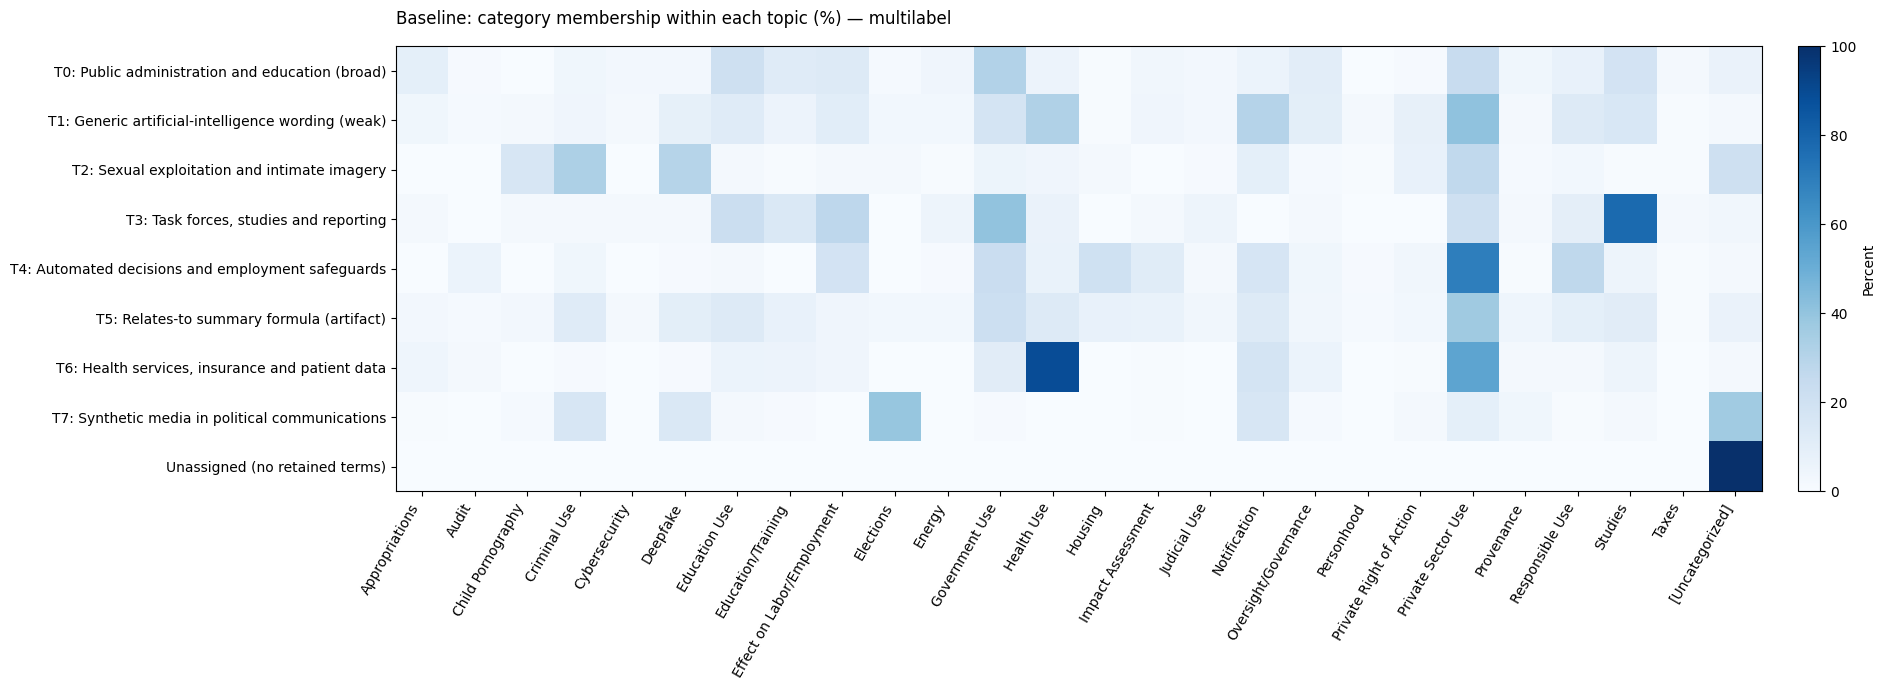

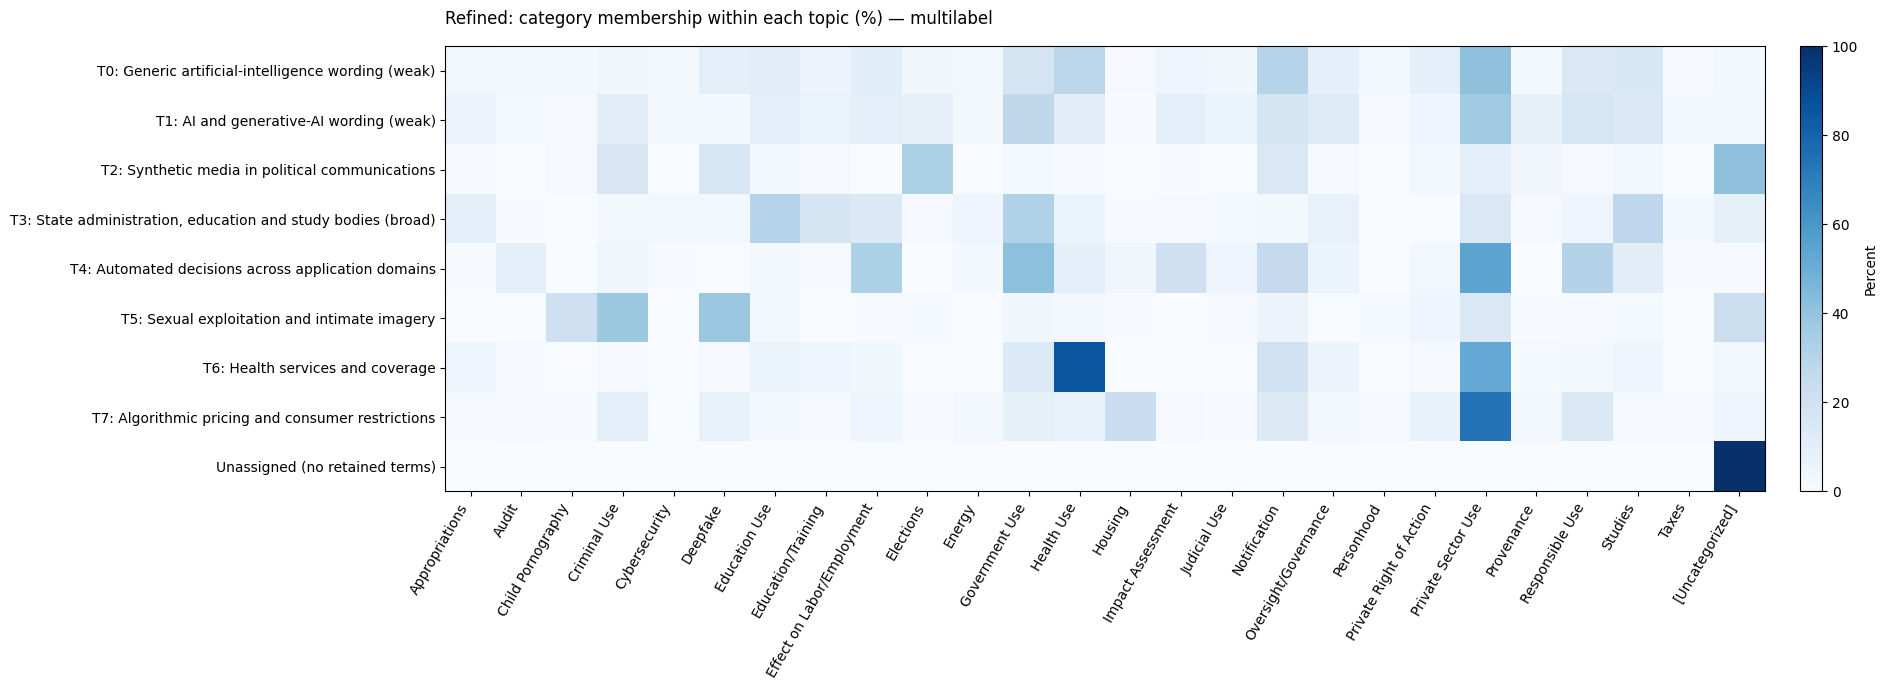

category,dominant_topic,Appropriations,Audit,Child Pornography,Criminal Use,Cybersecurity,Deepfake,Education Use,Education/Training,Effect on Labor/Employment,Elections,Energy,Government Use,Health Use,Housing,Impact Assessment,Judicial Use,Notification,Oversight/Governance,Personhood,Private Right of Action,Private Sector Use,Provenance,Responsible Use,Studies,Taxes,[Uncategorized]
,0,9,5,7,12,5,30,33,18,34,12,8,57,90,3,15,11,95,29,7,29,132,7,46,49,2,5
,1,20,5,4,36,9,6,34,22,35,28,8,95,36,2,34,19,62,43,4,15,128,28,55,51,6,10
,2,1,0,2,32,0,34,4,2,0,70,0,3,1,0,1,0,31,2,0,6,21,7,2,5,0,88
,3,47,4,1,10,15,13,153,86,72,5,24,164,27,4,5,7,10,37,1,1,75,6,21,142,9,43
,4,1,16,0,6,1,0,3,1,55,0,3,69,15,6,34,8,42,9,0,5,90,0,51,17,1,1
,5,0,0,85,156,1,157,9,0,3,5,0,15,10,2,0,4,23,1,5,19,59,3,2,5,0,93
,6,10,2,0,2,0,2,12,10,9,0,0,31,198,0,0,0,46,13,0,2,121,3,5,10,0,6
,7,2,4,2,34,0,26,6,2,15,2,10,30,24,81,4,2,47,11,3,24,266,9,49,4,3,17
,-1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


In [8]:
distribution_tables = {}
for prefix, bundle, names in [("baseline", baseline, topic_summary), ("refined", clean, clean_topics)]:
    distribution_tables[prefix] = distributions(work, bundle["W"], OUT, prefix)
    state_counts, state_shares, category_counts, category_shares = distribution_tables[prefix]
    row_names = {r.topic_id: f"T{r.topic_id}: {r.name}" for r in names.itertuples()}
    row_names[-1] = "Unassigned (no retained terms)"
    fig = heatmap(category_shares.rename(index=row_names),
        f"{prefix.title()}: category membership within each topic (%) — multilabel",
        OUT / f"{prefix}_topic_category_heatmap.png", percent=True, size=(19, 7))
    display(fig); plt.close(fig)
show(distribution_tables["refined"][2].reset_index())

## 6. Jurisdiction distributions: record counts and within-jurisdiction proportions

Counts assign one dominant topic to each record. The denominator for every jurisdiction is **all its included records**, including the single unassigned Illinois record. All 50 states and DC are displayed; small denominators can produce extreme percentages. Each column is a fitted topic, not a verified governance code, and weak topics remain visible.

The data describe the **corpus's captured records**, not legislative attention, policy quality, enacted law or the complete set of bills proposed in a state. Higher counts can reflect greater source coverage; within-state proportions do not remove this bias. The analysis retains repeated summaries/companion measures, pools years, and does not adjust for state size, publication practices or bill families.

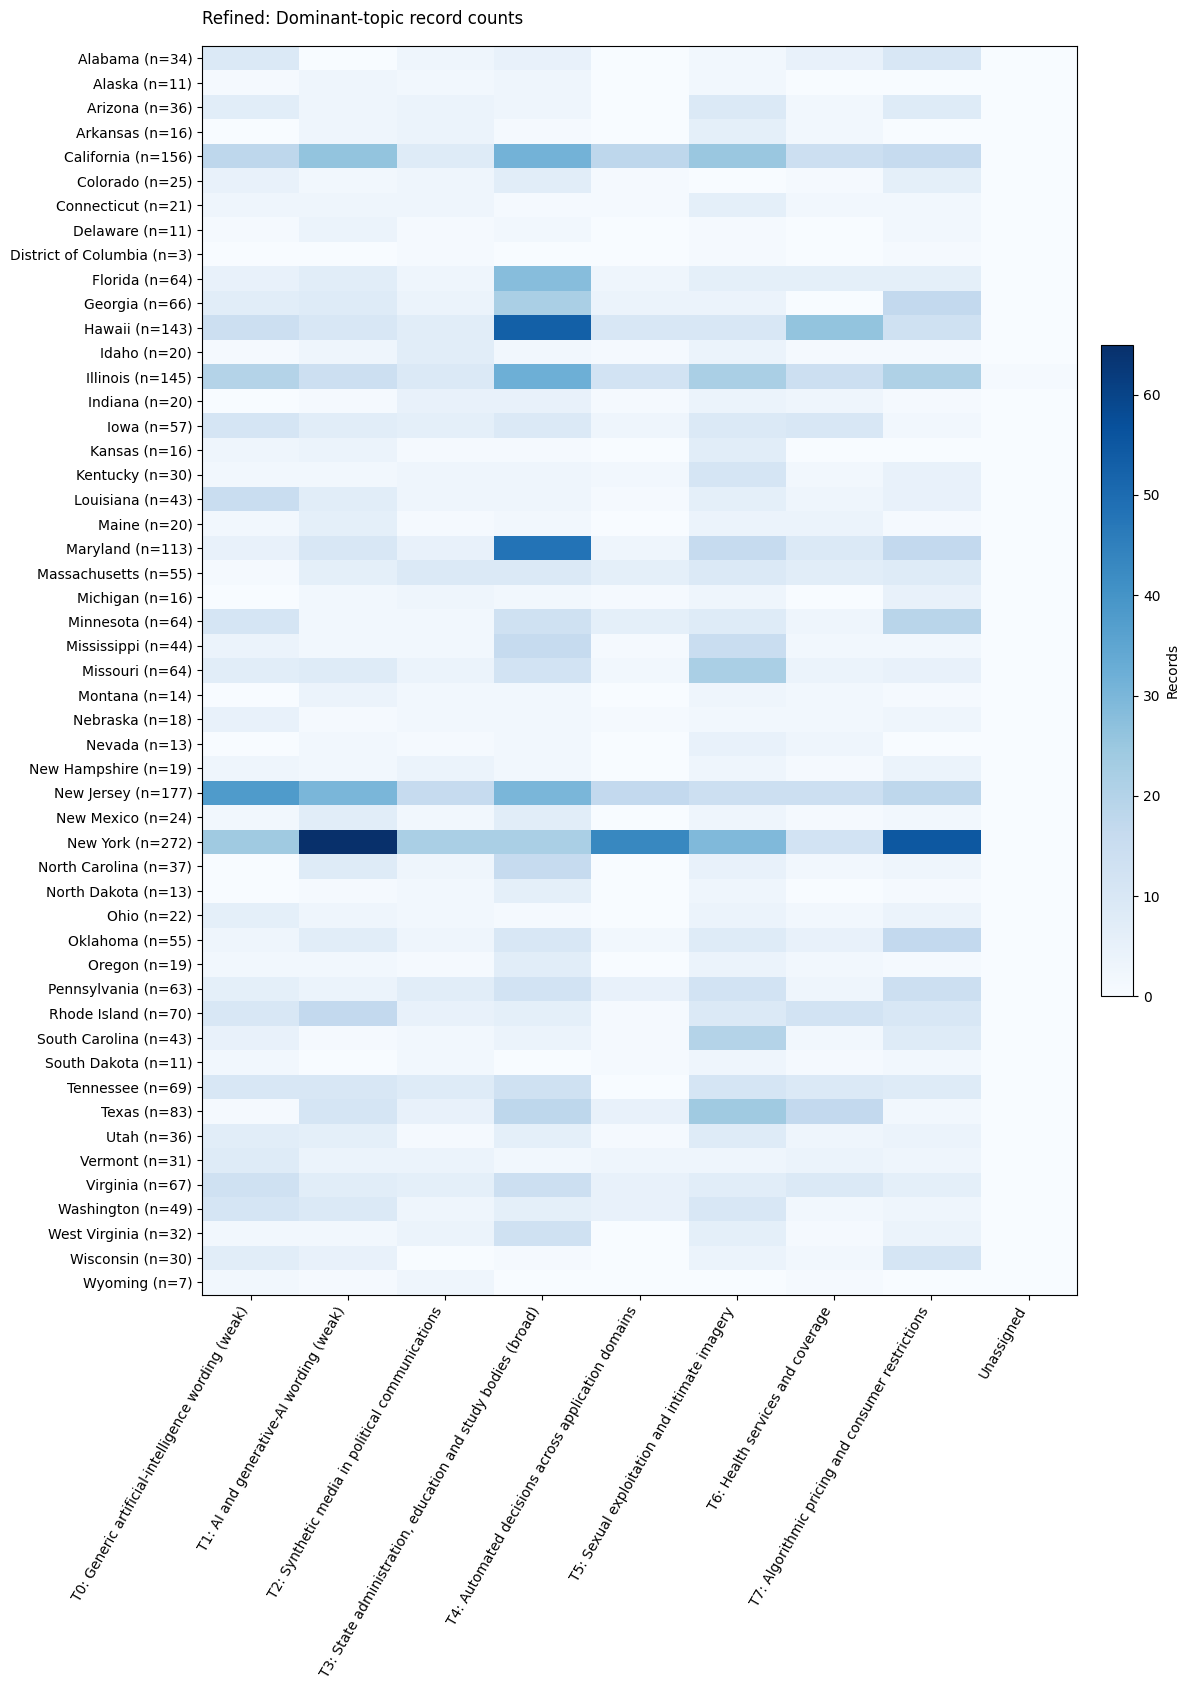

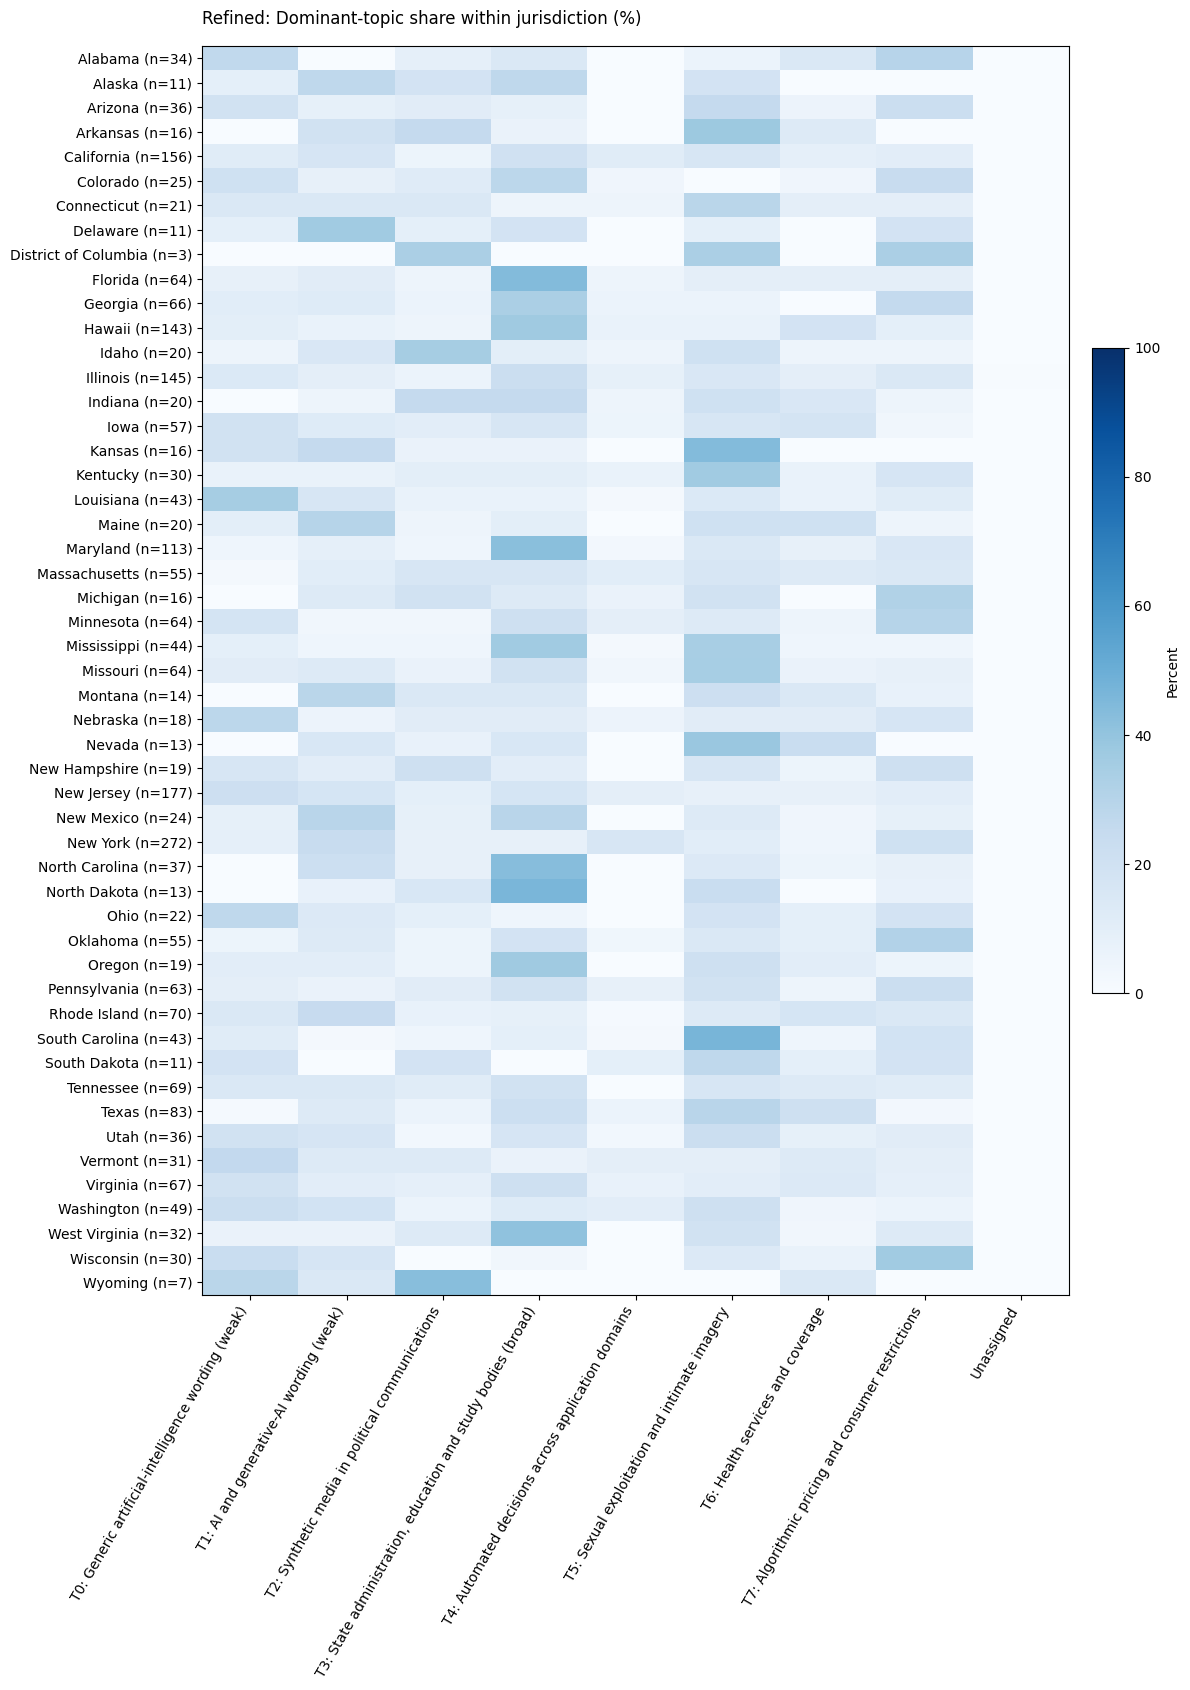

Both baseline and refined state tables/figures saved; refined figures displayed.


In [9]:
topic_captions = {"baseline": [r["name"] for r in labels["baseline"]],
                  "refined": [r["name"] for r in labels["legal"]]}
for prefix in ["baseline", "refined"]:
    counts, shares, _, _ = distribution_tables[prefix]
    denominators = work.groupby("Jurisdiction").size()
    row_names = {s: f"{s} (n={denominators[s]})" for s in counts.index}
    col_names = {t: f"T{t}: {topic_captions[prefix][t]}" if t >= 0 else "Unassigned" for t in counts.columns}
    for data, suffix, percent, title in [
        (counts, "counts", False, "Dominant-topic record counts"),
        (shares, "proportions", True, "Dominant-topic share within jurisdiction (%)")]:
        fig = heatmap(data.rename(index=row_names, columns=col_names),
            f"{prefix.title()}: {title}", OUT / f"{prefix}_state_topic_{suffix}.png",
            percent=percent, size=(12, 17))
        if prefix == "refined": display(fig)
        plt.close(fig)
print("Both baseline and refined state tables/figures saved; refined figures displayed.")

## 7. Eight provision-level cases, selected after topic inspection

The selection is **purposive and exploratory**: inspect baseline topics 3 and 4, read their top-weight candidates, then retain eight records that contrast domains, jurisdictions and obligations. Select only one Illinois Future of Work measure to avoid treating its many versions as independent corroboration. These eight cases are not a random sample or an estimate of prevalence. Source categories are kept as supplied; application domains below are annotations from the text.

**Relationship A — safeguards around automated decisions.** IN H 1421 and NY A 9601 (employment) and SC S 443 (coverage) prohibit sole reliance on automation and specify human oversight. NY S 6471-A (housing) and NY S 8115-B (lending) share notice and assessment requirements with the employment case, but do not establish an identical human-appeal right. The lending appeal specifically concerns incorrect personal information. SC's operative clause says **health care professional**, whereas its title/summary says **licensed physician**; the report uses the operative language and flags the unexamined cross-reference.

**Relationship B — study bodies with reporting duties.** IL S 2481 (workforce), UT H 168 (education), and CO S 240 (electronic discovery) create study/reporting structures across domains. Colorado's AI transcription provision is only one part of a wider electronic-discovery measure, so this supports a shared institutional approach, not a common substantive AI safeguard. Source categories already include `Studies` for some records: the result reveals a useful relation, not a wholly absent concept.

**Same category, different approach.** IL S 2481 and IN H 1421 both carry `Effect on Labor/Employment`, but the first establishes a study body and the second imposes employer-facing duties. Their topic separation complements the across-domain similarities.

Every excerpt below comes from the stored **original `Bill_Text`**, with a text checksum, section locator and original character offsets (zero-based, end exclusive). Matching is checked during execution. The corpus can contain amended/extracted text with lost markup; these are version-specific findings, not a statement that a proposal was enacted or remains current.

In [10]:
case_spec = json.loads((root / "notebooks/topic_case_review.json").read_text(encoding="utf-8"))
cases = case_evidence(work, case_spec["cases"], bundles, OUT)
case_positions = {sr: i for i, sr in enumerate(work.source_row)}
for name, bundle in [("baseline", baseline), ("refined", clean)]:
    cases[f"{name}_topic"] = [int(dominant_topics(bundle["W"])[case_positions[sr]]) for sr in cases.source_row]
    cases[f"{name}_rank_within_topic"] = [
        int(np.flatnonzero(np.argsort(-bundle["W"][:, int(dominant_topics(bundle["W"])[case_positions[sr]])],
                                     kind="stable") == case_positions[sr])[0] + 1)
        for sr in cases.source_row]
cases.to_csv(OUT / "case_analysis.csv", index=False)
show(cases[[*IDENTIFIERS, "NCSL_Category", "application_domain", "baseline_topic",
            "baseline_rank_within_topic", "refined_topic", "concrete_requirements", "differences_and_limits"]])
for row in cases.itertuples():
    display(Markdown(f"### Source row {row.source_row}: {row.Jurisdiction} {row.Bill_Number} ({row.Year})"))
    show(pd.DataFrame([{"Actor": row.applicable_actor, "Regulated action": row.regulated_action,
        "Requirement": row.concrete_requirements, "Limits": row.differences_and_limits,
        "Stored version date": row.Version_Date, "Stored status": row.Bill_Status,
        "Section and raw-character locators": row.evidence_locations_json,
        "Verbatim stored Bill_Text excerpts": row.evidence}]))

source_row,Jurisdiction,Bill_Number,Year,NCSL_Category,application_domain,baseline_topic,baseline_rank_within_topic,refined_topic,concrete_requirements,differences_and_limits
1856,Indiana,H 1421,2026,"Effect on Labor/Employment, Notification, Private Sector Use, Private Right of Action, Responsible Use",Employment,4,3,4,"No exclusive automated reliance; predeployment validation, annual independent bias testing with public results, experienced human corroboration, disclosure, and human dispute/appeal channels.",More extensive safeguards than SC S 443; a different experienced human hears an appeal. The employer definition excludes labor organizations except in their employer role. This is proposed text in the stored introduced version.
2258,New York,A 9601,2026,"Effect on Labor/Employment, Notification, Private Sector Use",Employment,4,7,4,"Meaningful human evaluation before final/adverse decisions, override authority, notice of automated use and data types, and human review on an unsuccessful applicant's request.",This short hiring-focused bill does not establish the same annual independent testing package as IN H 1421; the cited sections should not be generalized to every employment decision.
709,South Carolina,S 443,2025,Health Use; Private Sector Use,Health coverage,4,45,4,No coverage action based solely on AI/tool results; professional supervision and meaningful review when automated tools inform modification or denial of authorization.,"The title/summary says licensed physician, but operative subsection (C) says health care professional (section 44-30-20). No applicant notice, annual audit or human appeal package is stated in this short stored bill. The referenced definition was not independently examined."
575,New York,S 6471,2025,Housing; Private Sector Use; Impact Assessment,Housing applicant screening,4,42,4,"Annual disparate-impact analysis by an independent auditor; public analysis summary; notice about use, characteristics and data; denial reasons; at least 24-hour prior notice enabling an alternative selection process or accommodation request.","An alternative process/accommodation request is not an explicit universal right to a human override. Tool scope excludes non-discretionary software. Stored text is S 6471-A, while the source identifier omits the amendment suffix."
589,New York,S 8115,2025,Private Sector Use,Lending,4,8,4,"At least annual impact assessments signed by responsible human reviewers, assessments before material changes, public final reports, notice, and a 30-day correction/appeal route for denials based on incorrect personal information.",The appeal is conditional on incorrect personal information. Human review of an impact assessment does not establish review of every loan decision. The housing bill specifies an independent auditor; this text specifies signatures of responsible reviewers. Stored version is S 8115-B; federal banks and other listed institutions are excluded.
1456,Illinois,S 2481,2021,Effect on Labor/Employment,Workforce and employment,3,1,3,"Assess emerging technologies and workforce effects, propose training and other policies, and submit a final report to the Governor and General Assembly.",Dissolves on filing its final report; broader future-of-work remit than AI alone. IN H 1421 shares the Effect on Labor/Employment label but imposes direct employer obligations rather than establishing a study body. Repeated Illinois companion/version summaries are not independent evidence.
797,Utah,H 168,2025,Education Use; Studies,Education,3,13,3,"Study and recommend education AI policies, privacy safeguards and implementation guidelines; coordinate with the AI policy office; meet at least quarterly and report annually to legislative education committees.","Annual reporting contrasts with Illinois's final report and dissolution. The text addresses student privacy and educational agency without imposing a universal individual decision appeal. Stored plain text contains amendment remnants, so

### Source row 1856: Indiana H 1421 (2026)

### Source row 2258: New York A 9601 (2026)

Actor,Regulated action,Requirement,Limits,Stored version date,Stored status,Section and raw-character locators,Verbatim stored Bill_Text excerpts
Employers using automated applicant or resume screening.,Hiring decisions assisted by automated systems.,"Meaningful human evaluation before final/adverse decisions, override authority, notice of automated use and data types, and human review on an unsuccessful applicant's request.",This short hiring-focused bill does not establish the same annual independent testing package as IN H 1421; the cited sections should not be generalized to every employment decision.,01/21/2026,Pending,"[{""section"": ""Proposed Labor Law section 211-b(1)-(4)"", ""start_char"": 549, ""end_char_exclusive"": 1779}, {""section"": ""Proposed Labor Law section 211-b(6)(b)"", ""start_char"": 2339, ""end_char_exclusive"": 2531}]","Section 211-b. Human review of resume screening and hiring decisions. 1. An employer shall not use an automated system, including, but not limited to, an automated employment decision tool, algorithm, artificial intelligence system, or similar automated process to screen resumes or applicants unless there is a meaningful human review of the output of such automated system prior to making any final or adverse employment decision.\n2. No applicant for employment may be denied employment solely on the basis of an action by an automated system. Any recommendations, scores, rankings, or filters made or applied by an automated system shall be subject to human evaluation and override authority.\n3. Any employer that uses an automated system in the hiring process shall:\n(a) notify applicants that an automated system will be used;\n(b) describe, in plain language, the type of data analyzed; and\n(c) describe the role of the human reviewer in the final employment decision.\n4. When an automated system is used in the process of making employment decisions, an applicant who received an adverse employment decision shall be entitled to receive a human-conducted review of the employment decision upon the request of such applicant.\n\n[Next passage]\n\n(b) ""Meaningful human review"" means a deliberate evaluation conducted by a human with decision-making authority to modify or overturn the outcome or employment decision of an automated system."


### Source row 709: South Carolina S 443 (2025)

...

Actor,Regulated action,Requirement,Limits,Stored version date,Stored status,Section and raw-character locators,Verbatim stored Bill_Text excerpts
Illinois Future of Work Task Force.,Study of technology's effects on work and preparation of policy recommendations.,"Assess emerging technologies and workforce effects, propose training and other policies, and submit a final report to the Governor and General Assembly.",Dissolves on filing its final report; broader future-of-work remit than AI alone. IN H 1421 shares the Effect on Labor/Employment label but imposes direct employer obligations rather than establishing a study body. Repeated Illinois companion/version summaries are not independent evidence.,02/26/2021,Failed - Adjourned,"[{""section"": ""Sections 10(a)-(b)"", ""start_char"": 2783, ""end_char_exclusive"": 4391}, {""section"": ""Section 20"", ""start_char"": 6069, ""end_char_exclusive"": 6580}]","Section 10. Illinois Future of Work Task Force; duties and responsibilities.\n(a) The Illinois Future of Work Task Force is created. The Task Force shall be proactive and plan for the future of work while simultaneously addressing the state of work today.\n(b) The duties and responsibilities of the Task Force include the following:\n(1) The Illinois Future of Work Task Force shall identify and assess the new and emerging technologies that have the potential to significantly affect employment, wages, and skill requirements.\n(2) The Illinois Future of Work Task Force shall develop a set of job standards and working conditions that will ensure that future work in Illinois builds a vibrant middle class.\n(3) The Illinois Future of Work Task Force shall identify the potential jobs of the future and opportunities to shape those jobs for the improvement of life for all of Illinois.\n(4) The Illinois Future of Work Task Force shall compile research and best practices from other states and countries on how to deploy technology to benefit workers and the public good.\n(5) The Illinois Future of Work Task Force shall develop tools to assess the impact of proposed technologies and evaluate their costs and benefits on workers, employers, the public and the State.\n(6) The Illinois Future of Work Task Force shall identify policies and practices that will help businesses, workers, and communities thrive economically throughout the State of Illinois.\n(7) The Illinois Future of Work Task Force shall propose workforce development, training, education, and apprenticeship programs for the jobs of the future.\n\n[Next passage]\n\nSection 20. Report; dissolution.\n(a) The Illinois Future of Work Task Force shall issue a report based upon its findings in the course of performing its duties and responsibilities specified under Section 10. The report shall be written by an independent authority with subject matter expertise on the future of work.\n(b) The Illinois Future of Work Task Force shall submit its final report to the Governor and the General Assembly no later than November 1, 2022, and is dissolved upon the filing of its report."


### Source row 797: Utah H 168 (2025)

Actor,Regulated action,Requirement,Limits,Stored version date,Stored status,Section and raw-character locators,Verbatim stored Bill_Text excerpts
Utah Artificial Intelligence in Education Task Force.,Study and guidance on AI in public and higher education.,"Study and recommend education AI policies, privacy safeguards and implementation guidelines; coordinate with the AI policy office; meet at least quarterly and report annually to legislative education committees.","Annual reporting contrasts with Illinois's final report and dissolution. The text addresses student privacy and educational agency without imposing a universal individual decision appeal. Stored plain text contains amendment remnants, so changed membership details are not used as evidence.",02/24/2025,Failed,"[{""section"": ""Proposed section 36-29-113(10)-(14)"", ""start_char"": 3437, ""end_char_exclusive"": 5374}]","(10) The task force shall:\n(a) study and make recommendations to the Legislature, public education institutions, and higher education institutions on:\n(i) policies related to the use of artificial intelligence in education;\n(ii) guidelines for the implementation of artificial intelligence technologies in educational settings;\n(iii) protections for student privacy and data security in the context of artificial intelligence use;\n(iv) strategies for maximizing the beneficial uses of artificial intelligence in both public education and higher education;\n(v) promoting artificial intelligence literacy among students and staff;\n(vi) addressing potential risks associated with artificial intelligence use in education, including misinformation and bias;\n(vii) maintaining student and teacher agency when using artificial intelligence tools;\n(viii) advancing academic integrity in the context of artificial intelligence use; and\n(ix) ensuring equitable access to artificial intelligence tools and resources across student populations;\n(b) monitor national and international trends in artificial intelligence use in education;\n(c) identify best practices for integrating artificial intelligence into curriculum and instruction;\n(d) explore opportunities for collaboration between educational institutions and the artificial intelligence industry; and\n(e) coordinate efforts with the Office of Artificial Intelligence Policy to ensure alignment with statewide artificial intelligence initiatives.\n(11) The task force shall meet at least quarterly.\n(12) The chair of the task force may call additional meetings as necessary.\n(13) The task force shall comply with Title 52, Chapter 4, Open and Public Meetings Act.\n(14) The task force shall submit an annual report to the Education Interim Committee and the Higher Education Appropriations Subcommittee by November 30 of each year, summarizing the task force's activities and recommendations."


### Source row 80: Colorado S 240 (2025)

Actor,Regulated action,Requirement,Limits,Stored version date,Stored status,Section and raw-character locators,Verbatim stored Bill_Text excerpts
Colorado Electronic Discovery in Criminal Cases Task Force and participating agencies.,"Study of electronic-discovery costs, tools and equitable access, including AI transcription.","Gather information on discovery services and access; study AI transcription availability; submit findings, recommendations and legislative proposals to budget and technology committees.",AI is only one part of a broader electronic-discovery study. Agency information-sharing duties have legal and individual-rights exceptions. A common institutional approach does not establish common substantive AI safeguards.,04/28/2025,Enacted,"[{""section"": ""Proposed section 16-18-106(6)(c)(III)"", ""start_char"": 5539, ""end_char_exclusive"": 5715}, {""section"": ""Proposed section 16-18-106(7)-(8)"", ""start_char"": 7675, ""end_char_exclusive"": 8869}]","(III) THE ABILITY TO SEE AUTOMATED TRANSCRIPTIONS, USE ARTIFICIAL INTELLIGENCE TO GENERATE TRANSCRIPTIONS, OR USE ANY OTHER TOOLS TO EXPEDITE REVIEW OF DISCOVERY DOCUMENTS; AND\n\n[Next passage]\n\n(7) (a) LAW ENFORCEMENT AGENCIES, DISTRICT ATTORNEYS' OFFICES, THE OFFICE OF THE ATTORNEY GENERAL, THE OFFICE OF STATE PUBLIC DEFENDER, AND THE OFFICE OF ALTERNATE DEFENSE COUNSEL SHALL SHARE INFORMATION REQUESTED BY THE TASK FORCE REGARDING CONTRACTS, VENDORS, THE ELECTRONIC DISCOVERY PROCESS, AND COSTS BUT SHALL NOT SHARE INFORMATION THAT WOULD VIOLATE STATE OR FEDERAL LAWS, REGULATIONS, OR RULES OR THAT WOULD VIOLATE THE RIGHTS OF A PERSON INVOLVED IN A CRIMINAL CASE.\n(b) THE ENTITIES SPECIFIED IN SUBSECTION (7)(a) OF THIS SECTION SHALL RESPOND TO REQUESTS FROM THE TASK FORCE FOR INFORMATION PURSUANT TO SUBSECTION (7)(a) OF THIS SECTION IN GOOD FAITH AND PROVIDE INFORMATION WITHIN A REASONABLE TIME.\n(8) ON OR BEFORE NOVEMBER 1, 2025, THE TASK FORCE SHALL SUBMIT A REPORT TO THE JOINT BUDGET COMMITTEE AND THE JOINT TECHNOLOGY COMMITTEE THAT, AT A MINIMUM, DESCRIBES THE FOLLOWING:\n(a) THE WORK AND STUDY OF THE TASK FORCE;\n(b) THE FINDINGS AND RECOMMENDATIONS REGARDING THE ISSUES AND TOPICS CONSIDERED BY THE TASK FORCE AS DESCRIBED IN SUBSECTION (6) OF THIS SECTION; AND\n(c) LEGISLATIVE PROPOSALS AND EXPECTED RELATED COSTS BASED ON THE TASK FORCE'S FINDINGS AND RECOMMENDATIONS."


## 8. Stability of the selected relationships

Compare each selected pair's dominant-topic coassignment within a run, so topic numbers need not match between runs. Also export cosine similarity of the pair's weight vectors and component alignment across runs. One prespecified post-review contrast (workforce study body versus direct employer duties) is expected to remain separated.

The case pairs were selected after the initial fit, so stability is a sensitivity check on these examples, not an unbiased validation score. Different k, seeds and stopwords operate on this same corpus; no resampling, temporal replication or independent coding was performed. No numerical threshold was tuned to make a pair pass.

In [11]:
pair_results = pair_stability(work, bundles, case_spec["pairs"], OUT)
pair_results["method"] = pair_results.run_id.str.split("_").str[0].str.upper()
pair_results["relationship_preserved"] = np.where(pair_results.expected_relation.eq("similar"),
    pair_results.same_dominant_topic, ~pair_results.same_dominant_topic)
stability_summary = pair_results.groupby(["method", "a", "b", "relationship", "expected_relation"], sort=False).agg(
    runs=("run_id", "size"), preserved_runs=("relationship_preserved", "sum"),
    minimum_weight_cosine=("topic_weight_cosine", "min")).reset_index()
stability_summary.to_csv(OUT / "case_stability_summary.csv", index=False)
show(stability_summary)
show(pair_results.pivot(index="run_id", columns="relationship", values="same_dominant_topic").reset_index())
print("True means shared dominant topic; False is the desired result for the final same-category contrast.")

method,a,b,relationship,expected_relation,runs,preserved_runs,minimum_weight_cosine
NMF,1856,709,Employment/health: no sole automation and human oversight,similar,16,16,0.989672
NMF,2258,709,Hiring/health: meaningful human review,similar,16,16,0.995878
NMF,1856,575,"Employment/housing: testing and disclosure, different remedies",similar,16,16,0.980212
NMF,575,589,"Housing/lending: assessment and notice, different review scope",similar,16,16,0.996619
NMF,1456,797,Workforce/education: study body and reporting,similar,16,16,0.972817
NMF,1456,80,Workforce/justice: study body and reporting,similar,16,16,0.992201
NMF,797,80,Education/justice: study body and reporting,similar,16,16,0.973953
NMF,1456,1856,Same labor category: study institution versus direct safeguards,different,16,16,0.000000
LDA,1856,709,Employment/health: no sole automation and human oversight,similar,4,3,0.009307
LDA,2258,709,Hiring/health: meaningful human review,similar,4,4,0.817577


relationship,run_id,Education/justice: study body and reporting,Employment/health: no sole automation and human oversight,"Employment/housing: testing and disclosure, different remedies",Hiring/health: meaningful human review,"Housing/lending: assessment and notice, different review scope",Same labor category: study institution versus direct safeguards,Workforce/education: study body and reporting,Workforce/justice: study body and reporting
,lda_baseline_k10_seed42_batch,True,False,False,True,True,False,True,True
,lda_baseline_k12_seed42_batch,True,True,False,True,False,False,True,True
,lda_baseline_k5_seed42_batch,True,True,True,True,True,False,True,True
,lda_baseline_k8_seed42_batch,True,True,True,True,True,False,True,True
,nmf_baseline_k10_seed21_nndsvda,True,True,True,True,True,False,True,True
,nmf_baseline_k10_seed42_nndsvda,True,True,True,True,True,False,True,True
,nmf_baseline_k10_seed7_nndsvda,True,True,True,True,True,False,True,True
,nmf_baseline_k12_seed42_nndsvda,True,True,True,True,True,False,True,True
,nmf_baseline_k5_seed42_nndsvda,True,True,True,True,True,False,True,True
,nmf_baseline_k6_seed21_nndsvda,True,True,True,True,True,False,True,True


True means shared dominant topic; False is the desired result for the final same-category contrast.


In [12]:
display(Markdown(stability_report(pair_results)))

**NMF: 16 settings, 7 selected similarity pairs.** Shared dominant topic in 112/112 pair-setting checks. The contrasting pairs remain separated in 16/16 checks.

**LDA: 4 settings, 7 selected similarity pairs.** Shared dominant topic in 24/28 pair-setting checks. The contrasting pairs remain separated in 4/4 checks.

These are sensitivity results for cases selected after the initial fit, not validation of every topic boundary or independent confirmation. Topic-weight scaling, corpus coverage and limited LDA training remain limitations; provisions establish the specific commonalities.

### Additional check: NMF factor scaling changes dominant-topic counts

NMF factors have a scale ambiguity: multiplying one component of `H` by a positive constant and dividing its column in `W` by that constant leaves `W @ H` unchanged. Raw-weight argmax assignments can therefore change without any change in the reconstructed summaries. The original requested baseline and its top-five rankings remain available.

As a sensitivity check, give each component of `H` unit L1 mass and multiply its document-weight column by the original component mass. This preserves reconstruction and within-topic representative rankings. It is a descriptive alternative, not a probability calibration or a claim of a uniquely correct assignment. The table measures how many dominant assignments and within-state shares change, and rechecks the eight selected pair relations. Alternative state tables are exported for the baseline and refined models.

**State plots are conditional on the chosen weight convention.** They should not be described as intrinsic counts of policy categories. Stable selected cases do not establish stable corpus-wide topic prevalence.

In [13]:
scaling_summary, scaling_pairs = scaling_sensitivity(work, bundles, case_spec["pairs"], OUT)
show(scaling_summary)
scaling_pair_summary = scaling_pairs.groupby(["a", "b", "relationship"], sort=False).agg(
    settings=("run_id", "size"), preserved=("relationship_preserved", "sum")).reset_index()
show(scaling_pair_summary)
print("Unit-component-mass state counts/proportions: baseline_unit_mass_state_topic_*.csv and refined_unit_mass_state_topic_*.csv")

run_id,records,changed_dominant_records,changed_fraction,maximum_state_topic_shift_percentage_points
nmf_baseline_k5_seed42_nndsvda,2567,336,0.130892,28.571429
nmf_baseline_k6_seed42_nndsvda,2567,547,0.213089,46.875000
nmf_baseline_k8_seed42_nndsvda,2567,563,0.219322,42.857143
nmf_baseline_k10_seed42_nndsvda,2567,547,0.213089,29.850746
nmf_baseline_k12_seed42_nndsvda,2567,591,0.230230,36.363636
nmf_baseline_k6_seed7_nndsvda,2567,371,0.144527,28.571429
nmf_baseline_k6_seed21_nndsvda,2567,542,0.211141,42.857143
nmf_baseline_k8_seed7_nndsvda,2567,563,0.219322,42.857143
nmf_baseline_k8_seed21_nndsvda,2567,567,0.220880,42.857143
nmf_baseline_k10_seed7_nndsvda,2567,550,0.214258,29.850746


a,b,relationship,settings,preserved
1856,709,Employment/health: no sole automation and human oversight,16,16
2258,709,Hiring/health: meaningful human review,16,16
1856,575,"Employment/housing: testing and disclosure, different remedies",16,16
575,589,"Housing/lending: assessment and notice, different review scope",16,16
1456,797,Workforce/education: study body and reporting,16,16
1456,80,Workforce/justice: study body and reporting,16,16
797,80,Education/justice: study body and reporting,16,16
1456,1856,Same labor category: study institution versus direct safeguards,16,16


Unit-component-mass state counts/proportions: baseline_unit_mass_state_topic_*.csv and refined_unit_mass_state_topic_*.csv


## 9. Findings and limits

The useful output is a set of **text-supported relationships**, not a claim that there are exactly eight governance types. Employment and health-coverage cases share human-oversight language, while housing and lending cases connect through notification and assessment provisions with different remedies. Study-body legislation spans workforce, education and criminal-justice applications. The labor-category contrast illustrates how the same source label can conceal different policy instruments.

Limits to retain in the report:

- The model reads NCSL summaries, which can omit actors, exceptions and obligations and can be extremely short. Spelling (`AI` versus `artificial intelligence`) and summary templates affect the features. A summary-only model does not recover clause-level meaning by itself.
- Eight source texts were inspected with exact excerpt checks; an independent human reviewer has not validated the coding, and cross-referenced statutes/current versions were not independently checked. A saved `Bill_Text` field is not a guarantee of complete or markup-faithful official text.
- The source includes measures with limited AI relevance and repeated/near-identical summaries. Records are not independent policy innovations, and a state/year/bill string alone does not establish unique legislative identity. Cleaned-full-text duplicates are removed by shared preparation; an exact-summary deduplication sensitivity is exported below. No family-level resampling has been used.
- Categories are multilabel and partly missing or contaminated; they mix domains and governance approaches. Cross-category membership alone is not proof of novelty. The eight cases are a selected sample; they cannot estimate how common a requirement is.
- Dominant-topic counts depend on the NMF factor-scaling convention; the unit-component-mass check quantifies this sensitivity. Counts and state proportions describe this pooled snapshot. No political, causal, importance, legislative-success or current-law conclusions are drawn.
- Models here fit the whole descriptive corpus. If topics are later supplied to David's classifier, the vocabulary and model must be refitted inside each training split; these whole-corpus weights must not be treated as leakage-free supervised features. Separate train-only features are exported below for the agreed temporal split.

Next substantive extension: independent review of the eight cases and a larger contrasting sample, family-aware resampling, and clause/full-text modeling with version checks. When enabled, LDA is only a bounded secondary comparison; no full-text topic model has been fitted.

## Additional checks and supervised handoff

Following notebook 02, splits use the year of `introduction_date_iso`, not NCSL `Year`. Missing, invalid or out-of-range introduction dates are marked `excluded`, matching notebook 02; they remain transform-only rows for joins and never enter any supervised partition. The supervised vectorizer and NMF fit only introduction years 2019-2024, then transform 2025 validation and 2026 test records. Join by `source_row`; these topic IDs have their own meaning. Refit inside any later cross-validation folds. Summary sensitivity fits one record per identical cleaned summary and transforms the full population for a comparable assignment check. Sponsor tables are descriptive and exclude missing ratios from ratio averages.

In [14]:
# Separate training-only model; topic IDs do not inherit descriptive labels.
supervised_audit, summary_sensitivity = supplementary_analysis(work, baseline, OUT)
for prefix, bundle in [("baseline", baseline), ("refined", clean)]:
    sponsor_tables(work, bundle, OUT, prefix)
pd.DataFrame(identity_audit).to_csv(OUT / "previous_run_topic_alignment.csv", index=False)
show(pd.DataFrame([supervised_audit, summary_sensitivity]))
print("Sponsor tables are post-fit descriptive associations, not causal findings.")

split_date_column,split_reference,fit_years,validation_year,test_year,split_counts,excluded_source_rows,excluded_policy,input_column,warnings,topic_ids,scope,original_records,unique_summaries,removed_extra_summaries,evaluation_population,aligned_assignment_changes,adjusted_rand_index
introduction_date_iso,notebooks/02_data_split_exploration.ipynb: Intro_Year,"[2019, 2024]",2025.0,2026.0,"{'validation': 1016, 'test': 828, 'train': 722, 'excluded': 1}",[1377],"Missing/invalid dates and introduction years outside 2019-2026 are transformed but excluded from supervised partitions, matching notebook 02",NCSL_Summary_clean,[],Independent train-only model; descriptive labels do not apply,Temporal fit isolation only; repeated summaries across years may remain,NaN,NaN,NaN,NaN,NaN,NaN
NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2567.0,2307.0,260.0,all original records transformed by both models,380.0,0.691532


Sponsor tables are post-fit descriptive associations, not causal findings.


## 10. Reproducibility and validation

The analysis writes CSV tables, PNG figures, model objects and run metadata under `outputs/topic_analysis/`. The named notebook plus `src/topic_analysis.py`, `topic_labels.json`, and `topic_case_review.json` contain the analysis and review decisions. Raw data and shared preparation are unchanged.

Method reference: [scikit-learn's official NMF/LDA topic extraction example](https://scikit-learn.org/stable/auto_examples/applications/plot_topics_extraction_with_nmf_lda.html) uses TF–IDF for NMF and counts for LDA. This notebook uses the requested NMF parameters and its own bounded comparison settings. Shared preparation: [project repository](https://github.com/dhMontes/siads696-state-of-ai), original checkout commit `8ae9016bd7d6df06dbd4633202bab99c7c007653`. Source: [State AI Legislation Corpus v4](https://zenodo.org/records/20781731), frozen local `Final_Database.csv` snapshot; no live source update was merged.

In [15]:
# Validate identities, numeric outputs, evidence spans, labels and saved totals.
assert baseline_reps.groupby("topic_id").size().eq(5).all()
assert clean_reps.groupby("topic_id").size().eq(5).all()
assert cases.source_row.is_unique and 6 <= len(cases) <= 10
assert set(cases.source_row) <= set(work.source_row)
for name, bundle in bundles.items():
    assert bundle["W"].shape[0] == len(work)
    assert np.isfinite(bundle["W"]).all() and (bundle["W"] >= 0).all()
    assert np.array_equal(dominant_topics(bundle["W"]) == -1, bundle["X"].getnnz(axis=1) == 0)
for frame in [baseline_reps, clean_reps]:
    source = work.set_index("source_row")
    for r in frame.itertuples():
        assert source.loc[r.source_row, "Bill_Number"] == r.Bill_Number
        assert source.loc[r.source_row, TEXT] == r.NCSL_Summary_clean
for prefix, (counts, shares, cat_counts, cat_shares) in distribution_tables.items():
    assert counts.to_numpy().sum() == len(work)
    assert np.allclose(shares.sum(axis=1), 1)
    assert counts.sum(axis=1).equals(work.groupby("Jurisdiction").size())
    assert cat_shares.ge(0).all().all() and cat_shares.le(1).all().all()
    # Re-read disk artifacts, not only the in-memory values.
    saved_counts = pd.read_csv(OUT / f"{prefix}_state_topic_counts.csv", index_col=0)
    assert saved_counts.to_numpy().sum() == len(work)
for variant, frame in [("baseline", baseline_reps), ("legal", clean_reps)]:
    review = pd.DataFrame(labels[variant])
    if "evidence_source_rows" in review:
        for r in review.itertuples():
            assert set(r.evidence_source_rows.split(";")) == set(frame.loc[frame.topic_id.eq(r.topic_id), "source_row"])
assert not category_audit.parsed_categories.str.contains("Summary:|Associated Bills:").any()
assert all((OUT / name).exists() for name in ["baseline_representative_bills.csv", "refined_topic_summary.csv",
    "baseline_topic_category_heatmap.png", "refined_topic_category_heatmap.png", "case_analysis.csv",
    "model_comparison.csv", "case_pair_stability.csv", "refined_state_topic_counts.png", "refined_state_topic_proportions.png"])
joblib.dump({"baseline": {k: baseline[k] for k in ["model", "vectorizer"]},
             "refined": {k: clean[k] for k in ["model", "vectorizer"]},
             "source_rows": work.source_row.tolist(), "input_column": TEXT,
             "legal_stopwords": list(LEGAL_STOPWORDS)}, OUT / "summary_nmf_models.joblib")
metadata = {"timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "analysis": "NCSL-summary-only exploratory topics and stored-text case review",
    "input_column": TEXT, "post_fit_fields": ["NCSL_Category", "Jurisdiction", "Bill_Text"],
    "raw_sha256": sha256(root / "data/raw/Final_Database.csv"),
    "common_records_sha256": sha256(root / "data/processed/common_intake/common_records.csv"),
    "prepare_script_sha256": sha256(root / "src/prepare.py"),
    "analysis_script_sha256": sha256(root / "src/topic_analysis.py"),
    "review_sha256": sha256(root / "notebooks/topic_case_review.json"),
    "labels_sha256": sha256(root / "notebooks/topic_labels.json"),
    "source_row_convention": "one-based CSV record position; not physical line",
    "audit": audit, "zero_feature_source_rows": zero_rows.source_row.tolist(),
    "run_ids": comparison.run_id.tolist(), "include_lda": INCLUDE_LDA,
    "reviewer": "Codex-assisted; independent human validation pending",
    "python": platform.python_version(),
    "versions": {p: importlib.metadata.version(p) for p in ["pandas", "numpy", "scikit-learn", "scipy", "matplotlib", "nbformat", "nbclient"]},
    "validation": "Passed raw/common intake identity, excerpt matching, counts/proportions, finite weights and artifact checks",
    "scaling_sensitivity": scaling_summary.to_dict(orient="records")}
(OUT / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
show(pd.DataFrame([{"check": "Record and source preservation", "result": f"passed: {audit['included_records']:,} included records"},
    {"check": "Baseline representatives", "result": "passed: 8 topics x 5 records"},
    {"check": "State denominators", "result": "passed: all included records, including unassigned"},
    {"check": "Case excerpts", "result": "passed: literal spans from original Bill_Text"},
    {"check": "Independent human review", "result": "not yet performed"}]))
print("Outputs:", OUT)

check,result
Record and source preservation,"passed: 2,567 included records"
Baseline representatives,passed: 8 topics x 5 records
State denominators,"passed: all included records, including unassigned"
Case excerpts,passed: literal spans from original Bill_Text
Independent human review,not yet performed


Outputs: C:\Users\chian\OneDrive\Desktop\SIADS_696\siads696-state-of-ai\outputs\topic_analysis
